# Q1 — Data preparation, leakage and experimental design (Telco Customer Churn)

Sections: **Q1a** data audit · Q1b split comparison · Q1c preprocessing · Q1d leakage demo · Q1e audit table and failure modes.

**Protocol note.** Descriptive data-quality checks in Q1a (types, missing values, duplicates, ranges, category levels) fit nothing and are computed on the full data. Any analysis that involves the **target** and could influence modelling decisions (churn rate by feature) is computed on the **training split only**. The test split is never inspected.

In [26]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'utils.py').exists())
sys.path.insert(0, str(ROOT))

from src.utils import *
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

set_seed()
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')

raw = load_telco_raw()                # exactly as in the CSV
X, y, ids = load_telco()              # TotalCharges -> float, SeniorCitizen -> No/Yes, y -> 0/1
parts = load_split(X, y, CLF_SPLIT_FILE, ids=ids)
X_train, y_train = parts['X_train'], parts['y_train']
split_labels = pd.read_csv(CLF_SPLIT_FILE)['split']

print('raw:', raw.shape, '| X:', X.shape, '| train:', X_train.shape)

raw: (7043, 21) | X: (7043, 19) | train: (4225, 19)


## Q1a.1 — Overview: columns, types, roles

In [27]:
roles = {TELCO_ID: 'ID (not a feature)', TELCO_TARGET: 'target'}
roles.update({c: 'numeric' for c in NUM_COLS})
roles.update({c: 'categorical' for c in CAT_COLS})

types = pd.DataFrame({
    'column': raw.columns,
    'raw_dtype': [str(raw[c].dtype) for c in raw.columns],
    'role': [roles[c] for c in raw.columns],
    'n_unique': [raw[c].nunique() for c in raw.columns],
})
save_table(types, 'q1a_feature_types')
print(f'{raw.shape[0]} rows, {raw.shape[1]} columns -> '
      f'{len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical features, 1 ID, 1 target')
types

7043 rows, 21 columns -> 3 numeric + 16 categorical features, 1 ID, 1 target


,column,raw_dtype,role,n_unique
0,customerID,str,ID (not a feature),7043
1,gender,str,categorical,2
2,SeniorCitizen,int64,categorical,2
3,Partner,str,categorical,2
4,Dependents,str,categorical,2
5,tenure,int64,numeric,73
6,PhoneService,str,categorical,2
7,MultipleLines,str,categorical,3
8,InternetService,str,categorical,3
9,OnlineSecurity,str,categorical,3


## Q1a.2 — Class distribution

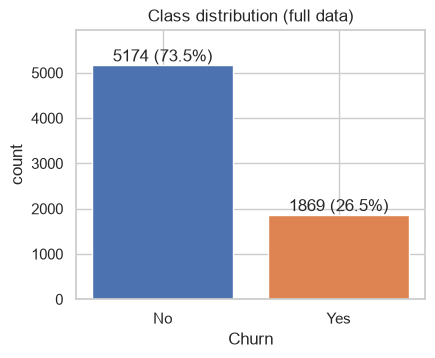

,Churn,count,fraction
0,No,5174,0.73463
1,Yes,1869,0.26537


In [28]:
cls = raw[TELCO_TARGET].value_counts().rename_axis('Churn').reset_index(name='count')
cls['fraction'] = cls['count'] / cls['count'].sum()
save_table(cls, 'q1a_class_distribution')

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(cls['Churn'], cls['count'], color=['#4C72B0', '#DD8452'])
for i, r in cls.iterrows():
    ax.text(i, r['count'], f"{r['count']} ({r['fraction']:.1%})", ha='center', va='bottom')
ax.set_ylim(0, cls['count'].max() * 1.15)
ax.set_xlabel('Churn'); ax.set_ylabel('count')
ax.set_title('Class distribution (full data)')
save_fig(fig, 'q1a_class_distribution'); plt.show()
cls

## Q1a.3 — Missing values

`TotalCharges` is stored as text in the CSV; missing entries appear as blank strings, not as NaN, so both are counted.

In [29]:
missing = pd.DataFrame({
    'NaN': raw.isna().sum(),
    'blank_string': raw.apply(lambda s: s.astype(str).str.strip().eq('').sum()),
})
missing = missing[missing.sum(axis=1) > 0]
print('Columns with NaN or blank strings:')
display(missing)

blank_mask = raw['TotalCharges'].astype(str).str.strip().eq('')
blank_rows = raw.loc[blank_mask, [TELCO_ID, 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', TELCO_TARGET]]
blank_rows = blank_rows.assign(split=split_labels[blank_mask].to_numpy())
save_table(blank_rows, 'q1a_blank_totalcharges')
print(f'{blank_mask.sum()} rows with blank TotalCharges '
      f'({blank_mask.mean():.3%} of the data). After load_telco() they are NaN: {X["TotalCharges"].isna().sum()}')
blank_rows

Columns with NaN or blank strings:


,NaN,blank_string
TotalCharges,0,11


11 rows with blank TotalCharges (0.156% of the data). After load_telco() they are NaN: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn,split
488,4472-LVYGI,0,52.55,,Two year,No,train
753,3115-CZMZD,0,20.25,,Two year,No,train
936,5709-LVOEQ,0,80.85,,Two year,No,train
1082,4367-NUYAO,0,25.75,,Two year,No,val
1340,1371-DWPAZ,0,56.05,,Two year,No,train
3331,7644-OMVMY,0,19.85,,Two year,No,train
3826,3213-VVOLG,0,25.35,,Two year,No,train
4380,2520-SGTTA,0,20.00,,Two year,No,train
5218,2923-ARZLG,0,19.70,,One year,No,train
6670,4075-WKNIU,0,73.35,,Two year,No,train


## Q1a.4 — Duplicates (with and without `customerID`)

Also checked: whether feature-identical rows carry **different** churn labels, and whether duplicate groups are **spread across splits** (a potential leakage route between train and val/test).

In [30]:
feat_cols = NUM_COLS + CAT_COLS
no_id = raw.drop(columns=TELCO_ID)
feat_dup_mask = raw[feat_cols].duplicated(keep=False)

dup_groups = raw.loc[feat_dup_mask, feat_cols + [TELCO_TARGET]].assign(split=split_labels[feat_dup_mask].to_numpy())
group_key = dup_groups[feat_cols].astype(str).agg('|'.join, axis=1)
per_group = dup_groups.groupby(group_key).agg(size=(TELCO_TARGET, 'size'),
                                              n_labels=(TELCO_TARGET, 'nunique'),
                                              n_splits=('split', 'nunique'))

dups = pd.DataFrame([
    ('identical rows incl. customerID (extra copies)', raw.duplicated().sum()),
    ('duplicated customerID values', raw[TELCO_ID].duplicated().sum()),
    ('identical rows excl. customerID, features+target (extra copies)', no_id.duplicated().sum()),
    ('identical rows excl. customerID, features only (extra copies)', raw[feat_cols].duplicated().sum()),
    ('rows belonging to a feature-duplicate group', feat_dup_mask.sum()),
    ('feature-duplicate groups', len(per_group)),
    ('groups with conflicting Churn labels', int((per_group['n_labels'] > 1).sum())),
    ('groups spread over more than one split', int((per_group['n_splits'] > 1).sum())),
], columns=['check', 'count'])
save_table(dups, 'q1a_duplicates')
display(dups)

print('Largest duplicate groups (feature columns identical):')
display(per_group.sort_values('size', ascending=False).head(5))
print('Example rows from duplicate groups:')
raw.loc[feat_dup_mask].sort_values(feat_cols).head(8)

,check,count
0,identical rows incl. customerID (extra copies),0
1,duplicated customerID values,0
2,"identical rows excl. customerID, features+targ...",22
3,"identical rows excl. customerID, features only...",40
4,rows belonging to a feature-duplicate group,73
5,feature-duplicate groups,33
6,groups with conflicting Churn labels,18
7,groups spread over more than one split,21


Largest duplicate groups (feature columns identical):


,size,n_labels,n_splits
1|20.2|20.2|Male|0|No|No|Yes|No|No|No internet service|No internet service|No internet service|No internet service|No internet service|No internet service|Month-to-month|No|Mailed check,4,2,2
1|69.9|69.9|Male|0|No|No|Yes|No|Fiber optic|No|No|No|No|No|No|Month-to-month|Yes|Electronic check,3,2,2
1|19.65|19.65|Female|0|No|No|Yes|No|No|No internet service|No internet service|No internet service|No internet service|No internet service|No internet service|Month-to-month|No|Mailed check,3,2,3
1|20.05|20.05|Male|0|No|No|Yes|No|No|No internet service|No internet service|No internet service|No internet service|No internet service|No internet service|Month-to-month|No|Mailed check,3,1,2
1|19.9|19.9|Female|0|No|No|Yes|No|No|No internet service|No internet service|No internet service|No internet service|No internet service|No internet service|Month-to-month|No|Mailed check,3,2,3


Example rows from duplicate groups:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
1736,7551-JOHTI,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.50,19.5,Yes
4172,1905-OEILC,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.50,19.5,No
542,2866-IKBTM,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1491,8605-ITULD,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
710,1029-QFBEN,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,Yes
6449,7601-WFVZV,Male,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.55,19.55,No
1049,8329-IBCTI,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,Yes
5170,7721-DVEKZ,Female,0,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.65,19.65,No


## Q1a.5 — Numeric ranges and anomalous values

,count,mean,std,min,25%,50%,75%,max,skew,n_zero,n_negative
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00,0.239540,11,0
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75,-0.220524,0,0
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80,0.961642,0,0


rows with tenure == 0              : 11
  of which TotalCharges is NaN     : 11
TotalCharges NaN with tenure > 0   : 0


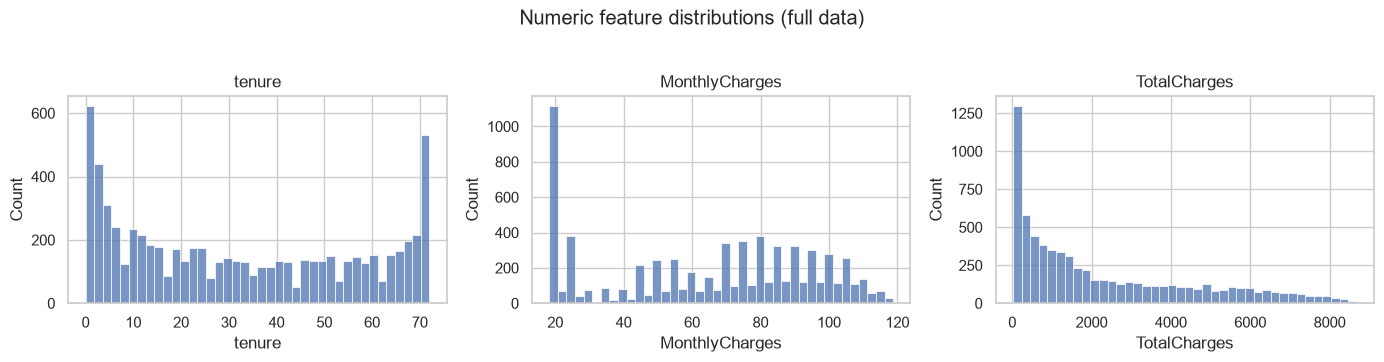

In [31]:
num = X[NUM_COLS]
summary = num.describe().T
summary['skew'] = num.skew()
summary['n_zero'] = (num == 0).sum()
summary['n_negative'] = (num < 0).sum()
save_table(summary.reset_index(names='feature'), 'q1a_numeric_summary')
display(summary)

t0 = X['tenure'] == 0
print('rows with tenure == 0              :', t0.sum())
print('  of which TotalCharges is NaN     :', X.loc[t0, 'TotalCharges'].isna().sum())
print('TotalCharges NaN with tenure > 0   :', X.loc[~t0, 'TotalCharges'].isna().sum())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, NUM_COLS):
    sns.histplot(num[c].dropna(), bins=40, ax=ax)
    ax.set_title(c)
fig.suptitle('Numeric feature distributions (full data)', y=1.03)
fig.tight_layout()
save_fig(fig, 'q1a_numeric_distributions'); plt.show()

## Q1a.6 — Redundancy: `TotalCharges` vs `tenure × MonthlyCharges`

Pearson:


,tenure,MonthlyCharges,TotalCharges,tenure_x_monthly
tenure,1.000,0.248,0.826,0.827
MonthlyCharges,0.248,1.000,0.651,0.652
TotalCharges,0.826,0.651,1.000,1.000
tenure_x_monthly,0.827,0.652,1.000,1.000


Spearman:


,tenure,MonthlyCharges,TotalCharges,tenure_x_monthly
tenure,1.000,0.276,0.889,0.890
MonthlyCharges,0.276,1.000,0.638,0.638
TotalCharges,0.889,0.638,1.000,1.000
tenure_x_monthly,0.890,0.638,1.000,1.000


Relative difference (TotalCharges - tenure*MonthlyCharges) / (tenure*MonthlyCharges):


,count,mean,std,min,25%,50%,75%,max
rel_diff,7032.0,0.000275,0.051159,-0.310644,-0.020454,0.0,0.019562,0.573454


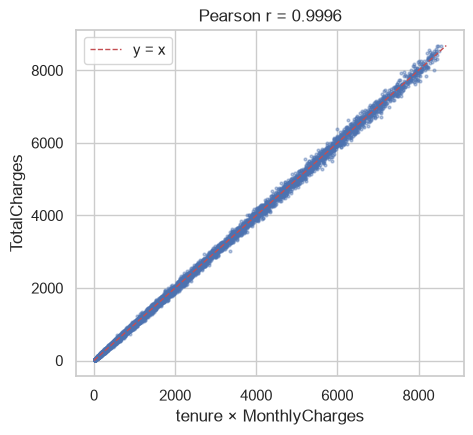

In [32]:
num_ext = num.assign(tenure_x_monthly=X['tenure'] * X['MonthlyCharges'])
corr_p = num_ext.corr(method='pearson')
corr_s = num_ext.corr(method='spearman')
save_table(corr_p.reset_index(names='feature'), 'q1a_numeric_corr_pearson')
save_table(corr_s.reset_index(names='feature'), 'q1a_numeric_corr_spearman')
print('Pearson:');  display(corr_p.round(3))
print('Spearman:'); display(corr_s.round(3))

rel_diff = ((X['TotalCharges'] - num_ext['tenure_x_monthly']) / num_ext['tenure_x_monthly']).dropna()
print('Relative difference (TotalCharges - tenure*MonthlyCharges) / (tenure*MonthlyCharges):')
display(rel_diff.describe().to_frame('rel_diff').T)

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(num_ext['tenure_x_monthly'], X['TotalCharges'], s=4, alpha=0.4)
lim = [0, np.nanmax(num_ext.values)]
ax.plot(lim, lim, 'r--', lw=1, label='y = x')
ax.set_xlabel('tenure × MonthlyCharges'); ax.set_ylabel('TotalCharges')
ax.set_title(f"Pearson r = {corr_p.loc['TotalCharges', 'tenure_x_monthly']:.4f}")
ax.legend()
save_fig(fig, 'q1a_totalcharges_scatter'); plt.show()

## Q1a.7 — Categorical levels: rare and dependent categories

In [33]:
rows = []
for c in CAT_COLS:
    for lvl, n in X[c].value_counts().items():
        rows.append({'feature': c, 'level': lvl, 'count': n, 'fraction': n / len(X)})
levels = pd.DataFrame(rows)
levels['rare_lt_5pct'] = levels['fraction'] < 0.05
save_table(levels, 'q1a_category_levels')
print('Rare levels (< 5% of rows):')
display(levels[levels['rare_lt_5pct']])

# Structurally dependent levels: a level that is fully determined by another column
services = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies']
checks = [(s, 'No internet service', 'InternetService', 'No') for s in services]
checks.append(('MultipleLines', 'No phone service', 'PhoneService', 'No'))
dep = pd.DataFrame([{
    'feature': f, 'level': lvl, 'determined_by': f'{parent} == {pval}',
    'rows_with_level': int((X[f] == lvl).sum()),
    'rows_with_condition': int((X[parent] == pval).sum()),
    'identical_rows': bool(((X[f] == lvl) == (X[parent] == pval)).all()),
} for f, lvl, parent, pval in checks])
save_table(dep, 'q1a_dependent_categories')
print('Dependent levels:')
display(dep)

print('Example cross-tab (InternetService x OnlineSecurity):')
pd.crosstab(X['InternetService'], X['OnlineSecurity'])

Rare levels (< 5% of rows):


,feature,level,count,fraction,rare_lt_5pct


Dependent levels:


,feature,level,determined_by,rows_with_level,rows_with_condition,identical_rows
0,OnlineSecurity,No internet service,InternetService == No,1526,1526,True
1,OnlineBackup,No internet service,InternetService == No,1526,1526,True
2,DeviceProtection,No internet service,InternetService == No,1526,1526,True
3,TechSupport,No internet service,InternetService == No,1526,1526,True
4,StreamingTV,No internet service,InternetService == No,1526,1526,True
5,StreamingMovies,No internet service,InternetService == No,1526,1526,True
6,MultipleLines,No phone service,PhoneService == No,682,682,True


Example cross-tab (InternetService x OnlineSecurity):


OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,1241,0,1180
Fiber optic,2257,0,839
No,0,1526,0


## Q1a.8 — Univariate relation to the target (TRAIN split only)

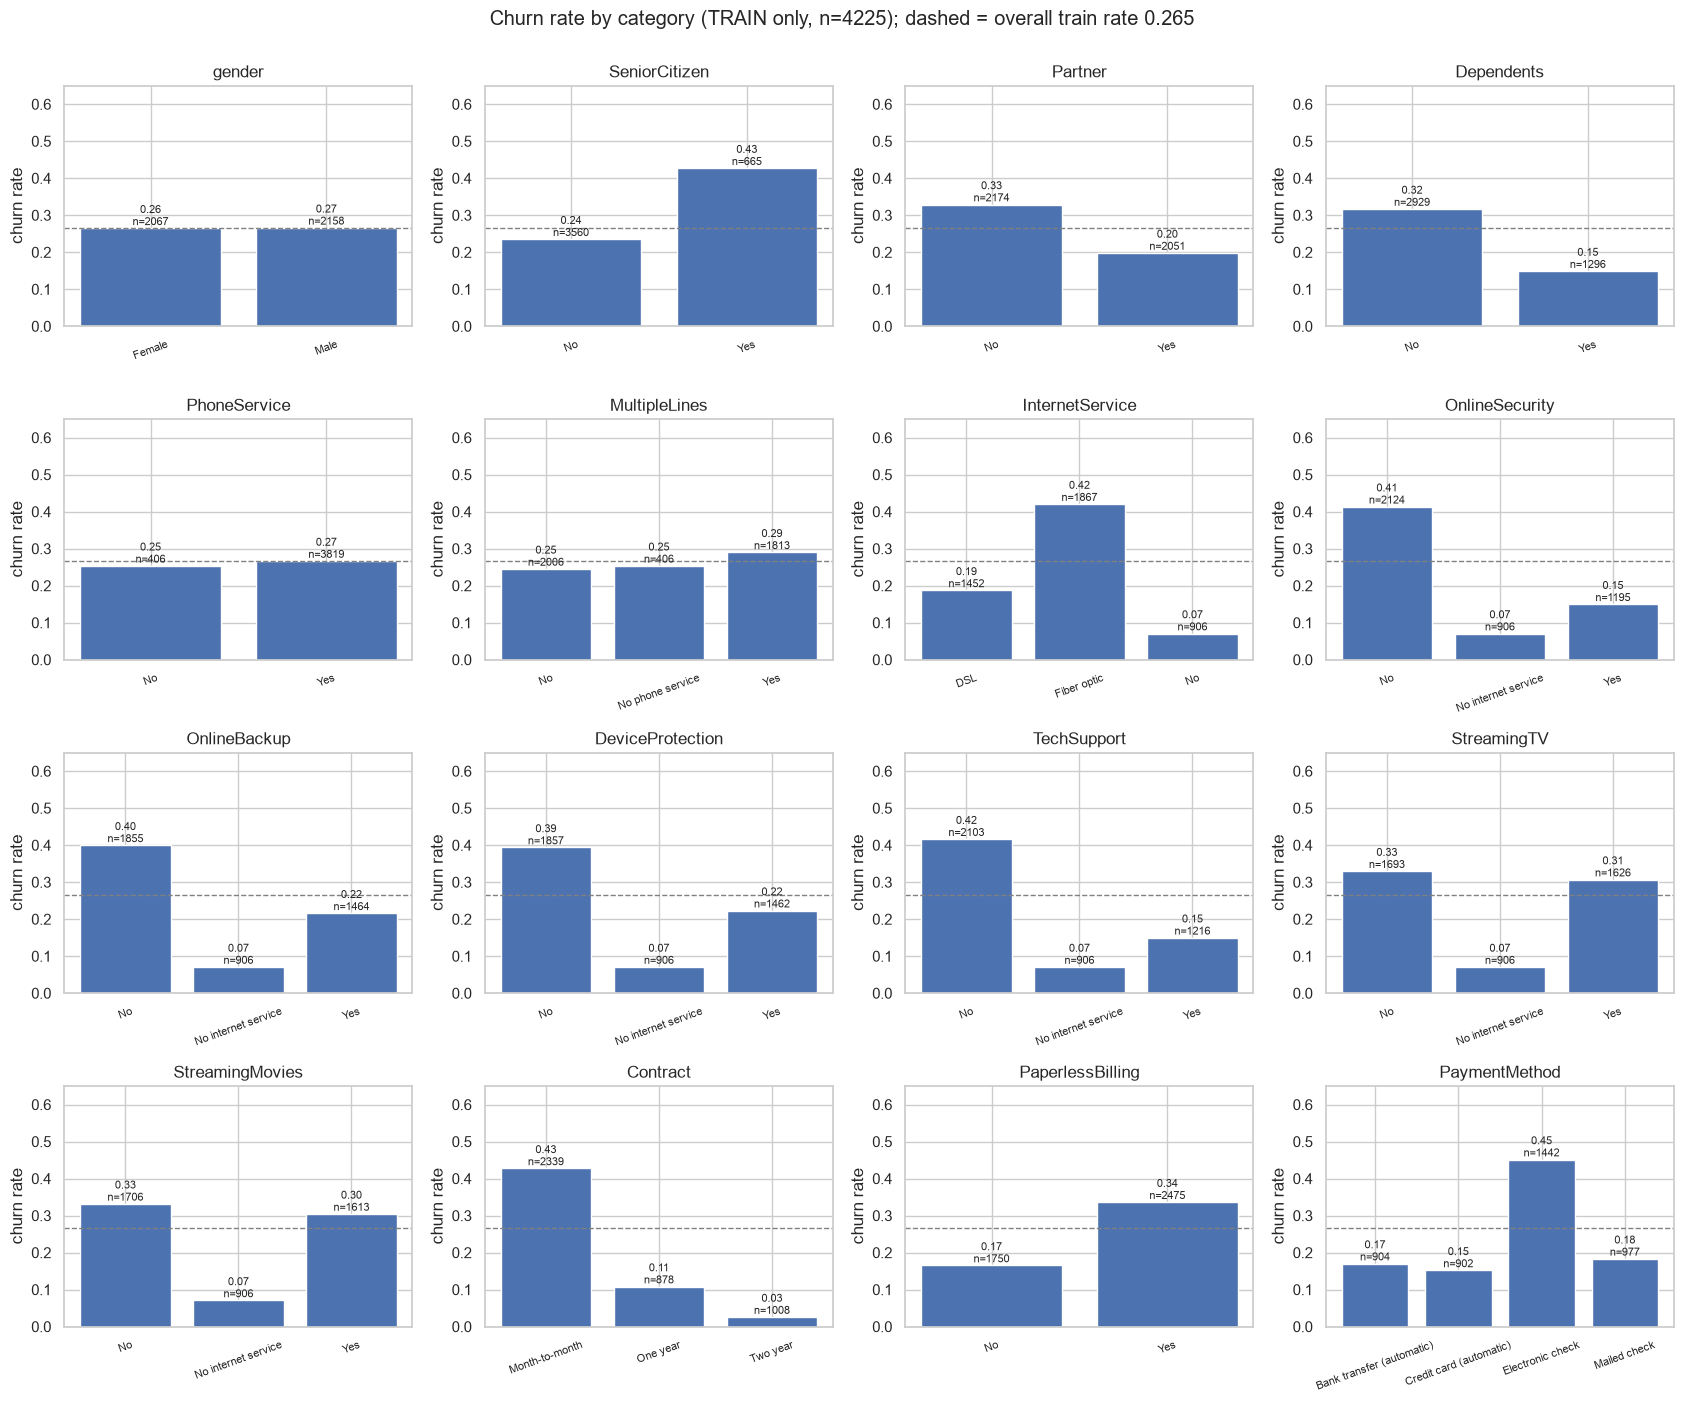

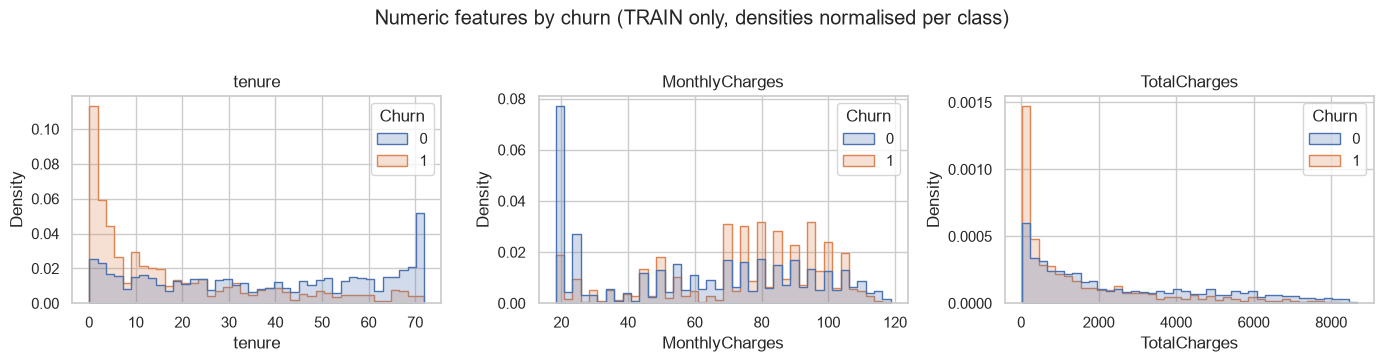

In [34]:
train = X_train.assign(Churn=y_train)
base_rate = y_train.mean()

rate_rows = []
fig, axes = plt.subplots(4, 4, figsize=(17, 14))
for ax, c in zip(axes.ravel(), CAT_COLS):
    g = train.groupby(c)['Churn'].agg(['mean', 'size'])
    ax.bar(g.index.astype(str), g['mean'], color='#4C72B0')
    for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
        ax.text(i, m, f'{m:.2f}\nn={n}', ha='center', va='bottom', fontsize=8)
    ax.axhline(base_rate, ls='--', color='gray', lw=1)
    ax.set_ylim(0, 0.65); ax.set_title(c); ax.set_ylabel('churn rate')
    ax.tick_params(axis='x', labelrotation=20, labelsize=8)
    rate_rows += [{'feature': c, 'level': lvl, 'n_train': int(n), 'churn_rate': m}
                  for lvl, m, n in zip(g.index, g['mean'], g['size'])]
fig.suptitle(f'Churn rate by category (TRAIN only, n={len(train)}); dashed = overall train rate {base_rate:.3f}', y=1.0)
fig.tight_layout()
save_fig(fig, 'q1a_churn_rate_by_category'); plt.show()

rates = pd.DataFrame(rate_rows)
save_table(rates, 'q1a_churn_rate_by_category_train')

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, NUM_COLS):
    sns.histplot(data=train, x=c, hue='Churn', bins=40, stat='density',
                 common_norm=False, element='step', ax=ax)
    ax.set_title(c)
fig.suptitle('Numeric features by churn (TRAIN only, densities normalised per class)', y=1.03)
fig.tight_layout()
save_fig(fig, 'q1a_numeric_by_churn_train'); plt.show()

## Q1a — Points for **you** to interpret in the report

*(Answer these from the outputs above in your own words; Claude does not write this text.)*

1. **Imbalance:** What is the exact class ratio? Which metric problems does it imply (accuracy of a majority-class baseline)?
2. **Missing values:** How many, in which column, and what do the affected rows have in common (`tenure`, `Contract`)? Are they truly *unknown* or *structurally* missing? Does median imputation make sense for them?
3. **Duplicates:** Are there duplicates with `customerID`? Without it? Do they have conflicting labels? Are they likely real distinct customers with identical profiles or data errors? Do duplicate groups cross splits, and does that matter?
4. **Anomalies:** Any impossible / out-of-range values? What about `tenure == 0`, skewness of `TotalCharges`?
5. **Redundancy:** How close is `TotalCharges` to `tenure × MonthlyCharges`? What does that mean for linear models (collinearity), NB (independence assumption) and importance analysis (Q4e)?
6. **Problematic predictors:** `customerID` (why it must be removed), rare levels, and the structurally dependent `No internet service` / `No phone service` levels (what one-hot encoding does with them).
7. **Target relations (train only):** Which features show the strongest univariate differences in churn rate? (Description only; these are not causal claims.)

---
# Q1b — Train/validation/test split: stratified vs random

### Q1b.1 — Exact sizes of the fixed split (created once in `00_setup_split.ipynb`)

Test 20% is separated first, the remaining 80% is split 75/25 into train/val → 60/20/20 of the data, stratified on `Churn`, `random_state = 463`.

In [35]:
clf_sizes = pd.read_csv(TABLES_DIR / 'clf_split_sizes.csv')   # produced by notebook 00 (fixed split)
clf_sizes

,split,n,fraction,target_mean
0,train,4225,0.599886,0.265325
1,val,1409,0.200057,0.265436
2,test,1409,0.200057,0.265436
3,full,7043,1.000000,0.265370


### Q1b.2 — Stratified vs random: 200 seeds

For each seed (463 … 662) the same two-stage 60/20/20 procedure used in `make_split()` is applied **with** and **without** stratification. For every part we record |churn rate of the part − churn rate of the full data|, in percentage points. These are only re-splits of the labels for illustration: no model is fitted and the fixed split from notebook 00 is not changed.

[timer] 200 seeds x 2 methods: 0.797 s
Full-data churn rate: 0.2654   (deviations in percentage points)


,method,split,mean,std,max,share_gt_1pp
0,stratified,train,0.004443,0.000000,0.004443,0.000
1,stratified,val,0.006661,0.000000,0.006661,0.000
2,stratified,test,0.006661,0.000000,0.006661,0.000
3,random,train,0.348773,0.265752,1.249995,0.020
4,random,val,0.848186,0.611348,2.845554,0.365
5,random,test,0.867350,0.669879,2.774581,0.365


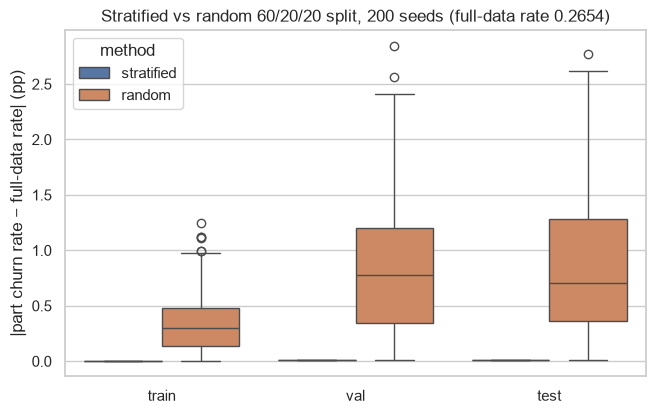

In [36]:
from sklearn.model_selection import train_test_split

N_SEEDS = 200
seeds = SEED + np.arange(N_SEEDS)          # 463, 464, ..., 662
y_all = y.to_numpy()
p_full = y_all.mean()
SPLIT_ORDER = ['train', 'val', 'test']


def split_positive_rates(y_arr, seed, stratify):
    """Same two-stage 60/20/20 procedure as make_split() in utils.py; returns the positive rate of each part."""
    idx = np.arange(len(y_arr))
    trval, test = train_test_split(idx, test_size=0.20, random_state=seed,
                                   stratify=y_arr if stratify else None)
    tr, va = train_test_split(trval, test_size=0.25, random_state=seed,
                              stratify=y_arr[trval] if stratify else None)
    return {'train': y_arr[tr].mean(), 'val': y_arr[va].mean(), 'test': y_arr[test].mean()}


recs = []
with timer(f'{N_SEEDS} seeds x 2 methods'):
    for s in seeds:
        for method, strat in [('stratified', True), ('random', False)]:
            for part, rate in split_positive_rates(y_all, s, strat).items():
                recs.append({'method': method, 'seed': s, 'split': part, 'pos_rate': rate,
                             'abs_dev_pp': 100 * abs(rate - p_full)})   # percentage points
dev = pd.DataFrame(recs)
dev.to_csv(TABLES_DIR / 'q1b_split_deviation_all_seeds.csv', index=False)

dev_summary = (dev.groupby(['method', 'split'])['abs_dev_pp']
                  .agg(mean='mean', std='std', max='max',
                       share_gt_1pp=lambda s: (s > 1).mean())
                  .reindex(pd.MultiIndex.from_product([['stratified', 'random'], SPLIT_ORDER]))
                  .rename_axis(['method', 'split']).reset_index())
save_table(dev_summary, 'q1b_split_deviation_summary')
print(f'Full-data churn rate: {p_full:.4f}   (deviations in percentage points)')
display(dev_summary)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.boxplot(data=dev, x='split', y='abs_dev_pp', hue='method', order=SPLIT_ORDER,
            hue_order=['stratified', 'random'], ax=ax)
ax.set_ylabel('|part churn rate − full-data rate| (pp)')
ax.set_xlabel('')
ax.set_title(f'Stratified vs random 60/20/20 split, {N_SEEDS} seeds (full-data rate {p_full:.4f})')
save_fig(fig, 'q1b_split_deviation_boxplot'); plt.show()

### Q1b.3 — When does random splitting fail? Effect of dataset size

The same comparison on random subsamples of size n (each seed draws its own subsample). For each split the **largest** deviation of the three parts from the subsample's own churn rate is recorded. Small datasets are where random splitting becomes unreliable.

[timer] sample-size experiment: 2.600 s


mean               p95               max           
method random stratified random stratified random stratified
n                                                           
100      9.98       1.35  20.00       3.00  31.00       3.00
250      6.69       0.58  14.00       1.20  20.40       1.20
500      4.10       0.28   8.20       0.60  11.60       0.60
1000     2.97       0.13   6.11       0.30   8.40       0.30
2000     2.24       0.07   4.15       0.15   5.90       0.15
7043     1.19       0.01   2.28       0.01   2.85       0.01

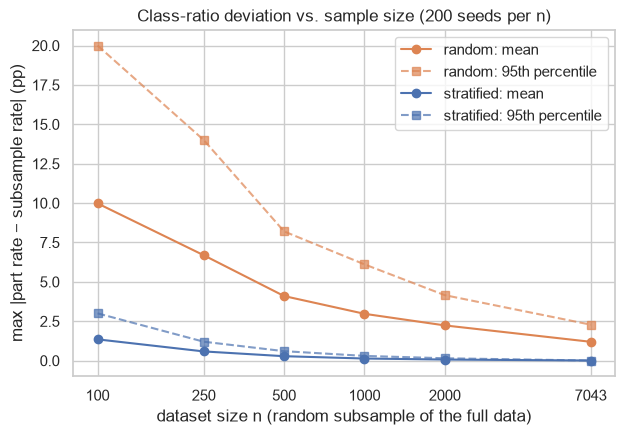

In [37]:
SIZES = [100, 250, 500, 1000, 2000, len(y_all)]

recs = []
with timer('sample-size experiment'):
    for n in SIZES:
        for s in seeds:
            rng = np.random.default_rng(s)
            sub = y_all[rng.choice(len(y_all), size=n, replace=False)] if n < len(y_all) else y_all
            p_sub = sub.mean()
            for method, strat in [('stratified', True), ('random', False)]:
                rates = split_positive_rates(sub, s, strat)
                recs.append({'n': n, 'method': method, 'seed': s,
                             'max_abs_dev_pp': 100 * max(abs(r - p_sub) for r in rates.values())})
size_dev = pd.DataFrame(recs)

size_summary = (size_dev.groupby(['n', 'method'])['max_abs_dev_pp']
                        .agg(mean='mean', p95=lambda s: s.quantile(0.95), max='max')
                        .reset_index())
save_table(size_summary, 'q1b_deviation_vs_sample_size')
display(size_summary.pivot(index='n', columns='method', values=['mean', 'p95', 'max']).round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
for method, color in [('random', '#DD8452'), ('stratified', '#4C72B0')]:
    d = size_summary[size_summary['method'] == method]
    ax.plot(d['n'], d['mean'], 'o-', color=color, label=f'{method}: mean')
    ax.plot(d['n'], d['p95'], 's--', color=color, alpha=0.7, label=f'{method}: 95th percentile')
ax.set_xscale('log')
ax.set_xticks(SIZES); ax.set_xticklabels(SIZES)
ax.set_xlabel('dataset size n (random subsample of the full data)')
ax.set_ylabel('max |part rate − subsample rate| (pp)')
ax.set_title(f'Class-ratio deviation vs. sample size ({N_SEEDS} seeds per n)')
ax.legend()
save_fig(fig, 'q1b_deviation_vs_sample_size'); plt.show()

### Q1b.4 — Class ratio inside CV folds: `StratifiedKFold` vs `KFold`

Tuning uses 5-fold CV **on the training split** (4,225 rows), so fold composition matters too. Shown for the full training split and for a tiny random subsample (n = 30) of it, where a fold can end up with **no churners at all** — the situation warned about in the lecture (a class missing from a CV fold makes F1/AUC for that fold undefined or misleading). Uses training labels only.

[timer] CV fold composition: 0.353 s


,n,method,fold_size,fold_rate_std,min_pos_in_fold,share_folds_zero_pos
0,30,KFold,6.0,0.180685,0,0.155
1,30,StratifiedKFold,6.0,0.104949,0,0.014
2,4225,KFold,845.0,0.013568,184,0.000
3,4225,StratifiedKFold,845.0,0.000474,224,0.000


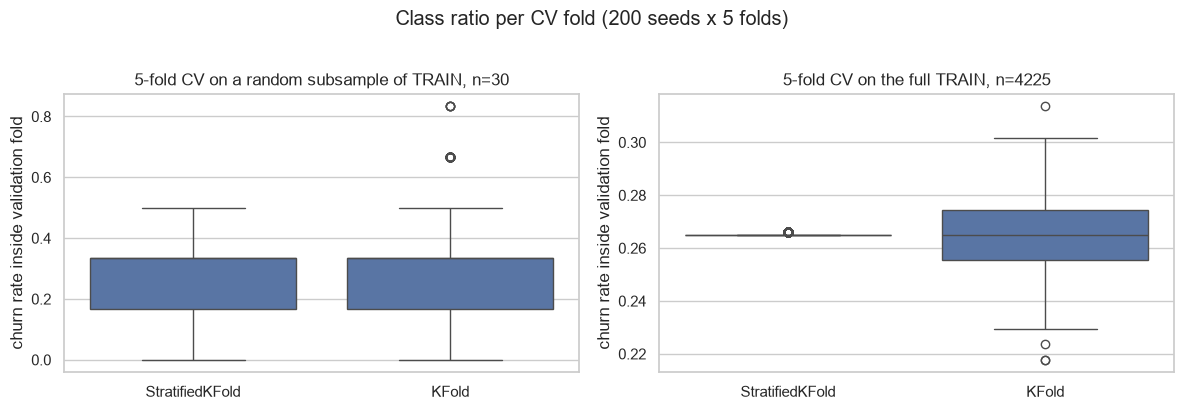

In [38]:
import warnings
from sklearn.model_selection import KFold, StratifiedKFold

y_tr = y_train.to_numpy()
CV_SIZES = [30, len(y_tr)]

recs = []
with timer('CV fold composition'), warnings.catch_warnings():
    warnings.simplefilter('ignore')        # StratifiedKFold warns when a class has < 5 members
    for n in CV_SIZES:
        for s in seeds:
            rng = np.random.default_rng(s)
            sub = y_tr[rng.choice(len(y_tr), size=n, replace=False)] if n < len(y_tr) else y_tr
            for method, cv in [('StratifiedKFold', StratifiedKFold(5, shuffle=True, random_state=s)),
                               ('KFold', KFold(5, shuffle=True, random_state=s))]:
                for k, (_, va_i) in enumerate(cv.split(np.zeros(n), sub)):
                    recs.append({'n': n, 'method': method, 'seed': s, 'fold': k,
                                 'pos_in_fold': int(sub[va_i].sum()), 'fold_size': len(va_i),
                                 'fold_rate': sub[va_i].mean()})
folds = pd.DataFrame(recs)

fold_summary = (folds.groupby(['n', 'method'])
                     .agg(fold_size=('fold_size', 'mean'),
                          fold_rate_std=('fold_rate', 'std'),
                          min_pos_in_fold=('pos_in_fold', 'min'),
                          share_folds_zero_pos=('pos_in_fold', lambda s: (s == 0).mean()))
                     .reset_index())
save_table(fold_summary, 'q1b_cv_fold_composition')
display(fold_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, n in zip(axes, CV_SIZES):
    sub = folds[folds['n'] == n]
    which = 'a random subsample of' if n < len(y_tr) else 'the full'
    sns.boxplot(data=sub, x='method', y='fold_rate', ax=ax)
    ax.set_title(f'5-fold CV on {which} TRAIN, n={n}')
    ax.set_ylabel('churn rate inside validation fold'); ax.set_xlabel('')
fig.suptitle(f'Class ratio per CV fold ({N_SEEDS} seeds x 5 folds)', y=1.02)
fig.tight_layout()
save_fig(fig, 'q1b_cv_fold_rates'); plt.show()

## Q1b — Points for **you** to interpret in the report

*(Answer these from the outputs above in your own words; Claude does not write this text.)*

1. **Exact split sizes:** report n and fraction of train/val/test (Table `clf_split_sizes`) and why 7,043 cannot be split exactly 60/20/20.
2. **Stratified vs random (200 seeds):** how large is the class-ratio deviation for each method (mean, max, in percentage points)? How often does random exceed 1 pp on val/test? Is that difference practically important for a val/test set of 1,409 rows with ~374 positives?
3. **Sample size:** how does the deviation of random splitting change as n shrinks? Around which n does it become a real problem?
4. **CV folds:** with a small training set (n = 30), how often does plain `KFold` produce a fold with **zero** churners, and what happens to Macro-F1 / ROC-AUC on such a fold? (Link to the lecture warning about a class missing in a CV fold.)
5. **When does stratification fail or not suffice?** (not shown by code — discuss): classes with fewer members than folds; grouped data (same customer/household in several rows → `GroupKFold`); time-ordered data (future leaking into past → `TimeSeriesSplit`); regression targets (stratify on binned target); multi-label targets.
6. **Protocol:** why computing the class ratio of the test part here does not count as "looking at the test set" (no model, no decision depends on it).

---
# Q1c — Preprocessing pipeline

`build_preprocessor()` in `src/utils.py` (a `ColumnTransformer`):

| Column group | Step 1 | Step 2 |
|---|---|---|
| numeric: `tenure`, `MonthlyCharges`, `TotalCharges` | `SimpleImputer(strategy='median')` | `StandardScaler()` (switchable: `scale=False`) |
| categorical: 16 columns incl. `SeniorCitizen` | `SimpleImputer(strategy='most_frequent')` | `OneHotEncoder(handle_unknown='ignore')` |

`customerID` is dropped (`remainder='drop'`). The transformer is always placed **inside a `Pipeline`** with the model, so in cross-validation it is re-fitted on the training part of each fold only.

### Q1c.1 — The fitted pipeline

In [39]:
from sklearn.pipeline import Pipeline

pre = build_preprocessor(scale=True)      # defined in src/utils.py
pre.fit(X_train)                          # fitted on the TRAINING split only
feat_names = pre.get_feature_names_out()
n_onehot = len(feat_names) - len(NUM_COLS)
print(f'{X_train.shape[1]} input columns -> {len(feat_names)} model features '
      f'({len(NUM_COLS)} scaled numeric + {n_onehot} one-hot)')
save_table(pd.DataFrame({'output_feature': feat_names}), 'q1c_output_features')
print(list(feat_names))
pre                                        # interactive diagram of the ColumnTransformer

19 input columns -> 46 model features (3 scaled numeric + 43 one-hot)
['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'cat__gender_Female', 'cat__gender_Male', 'cat__SeniorCitizen_No', 'cat__SeniorCitizen_Yes', 'cat__Partner_No', 'cat__Partner_Yes', 'cat__Dependents_No', 'cat__Dependents_Yes', 'cat__PhoneService_No', 'cat__PhoneService_Yes', 'cat__MultipleLines_No', 'cat__MultipleLines_No phone service', 'cat__MultipleLines_Yes', 'cat__InternetService_DSL', 'cat__InternetService_Fiber optic', 'cat__InternetService_No', 'cat__OnlineSecurity_No', 'cat__OnlineSecurity_No internet service', 'cat__OnlineSecurity_Yes', 'cat__OnlineBackup_No', 'cat__OnlineBackup_No internet service', 'cat__OnlineBackup_Yes', 'cat__DeviceProtection_No', 'cat__DeviceProtection_No internet service', 'cat__DeviceProtection_Yes', 'cat__TechSupport_No', 'cat__TechSupport_No internet service', 'cat__TechSupport_Yes', 'cat__StreamingTV_No', 'cat__StreamingTV_No internet service', 'cat__StreamingTV_Yes', '

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

### Q1c.2 — Evidence that every statistic is learned from the training split only

The imputer and scaler store what they learned (`statistics_`, `mean_`, `scale_`). These must equal the statistics of the **training split**. After transformation, the training features have mean 0 / std 1 exactly, while validation features do not — exactly what should happen when validation is transformed with training statistics.

In [40]:
num_steps = pre.named_transformers_['num'].named_steps
train_median = X_train[NUM_COLS].median()
train_imputed = X_train[NUM_COLS].fillna(train_median)

learned = pd.DataFrame({
    'learned_imputer_median': num_steps['impute'].statistics_,
    'train_median': train_median.to_numpy(),
    'learned_scaler_mean': num_steps['scale'].mean_,
    'train_mean_after_imputation': train_imputed.mean().to_numpy(),
    'learned_scaler_std': num_steps['scale'].scale_,
    'train_std_after_imputation': train_imputed.std(ddof=0).to_numpy(),
}, index=NUM_COLS)
assert np.allclose(learned['learned_imputer_median'], learned['train_median'])
assert np.allclose(learned['learned_scaler_mean'], learned['train_mean_after_imputation'])
assert np.allclose(learned['learned_scaler_std'], learned['train_std_after_imputation'])
print('[ok] every statistic stored in the pipeline equals the TRAIN statistic')
save_table(learned.reset_index(names='feature'), 'q1c_learned_statistics')
display(learned)

X_val = parts['X_val']
Z_tr = pd.DataFrame(pre.transform(X_train), columns=feat_names, index=X_train.index)
Z_va = pd.DataFrame(pre.transform(X_val), columns=feat_names, index=X_val.index)
num_out = [f'num__{c}' for c in NUM_COLS]
after = pd.DataFrame({
    'train_mean': Z_tr[num_out].mean(), 'train_std': Z_tr[num_out].std(ddof=0),
    'val_mean': Z_va[num_out].mean(), 'val_std': Z_va[num_out].std(ddof=0),
})
save_table(after.reset_index(names='feature'), 'q1c_scaled_train_vs_val')
print('Scaled numeric features: train is exactly 0/1 by construction, validation only approximately:')
after

[ok] every statistic stored in the pipeline equals the TRAIN statistic


,learned_imputer_median,train_median,learned_scaler_mean,train_mean_after_imputation,learned_scaler_std,train_std_after_imputation
tenure,29.00,29.00,32.302249,32.302249,24.377461,24.377461
MonthlyCharges,70.40,70.40,64.865006,64.865006,30.005704,30.005704
TotalCharges,1399.35,1399.35,2271.889337,2271.889337,2246.705786,2246.705786


Scaled numeric features: train is exactly 0/1 by construction, validation only approximately:


,train_mean,train_std,val_mean,val_std
num__tenure,9.249669e-18,1.0,-0.011846,1.023988
num__MonthlyCharges,4.734149e-16,1.0,-0.007161,1.009987
num__TotalCharges,1.126778e-16,1.0,0.003256,1.035856


### Q1c.3 — What happens to missing values and unseen categories?

The rows with missing `TotalCharges` (train and validation) after the pipeline, and a **synthetic** row with a category level that never occurs in training, to show `handle_unknown='ignore'`.

In [41]:
X_trval = pd.concat([X_train, X_val])
Z_trval = pd.concat([Z_tr, Z_va])
nan_idx = X_trval.index[X_trval['TotalCharges'].isna()]

fate = pd.DataFrame({
    'split': ['train' if i in X_train.index else 'val' for i in nan_idx],
    'tenure': X_trval.loc[nan_idx, 'tenure'],
    'TotalCharges_raw': X_trval.loc[nan_idx, 'TotalCharges'],
    'TotalCharges_imputed': num_steps['impute'].statistics_[NUM_COLS.index('TotalCharges')],
    'TotalCharges_scaled': Z_trval.loc[nan_idx, 'num__TotalCharges'],
}, index=nan_idx)
save_table(fate.reset_index(names='row'), 'q1c_missing_value_fate')
assert not Z_tr.isna().any().any() and not Z_va.isna().any().any()
print('[ok] no NaN left after preprocessing (train and val)')
display(fate)

# Unseen category: a SYNTHETIC copy of one validation row with a level that never occurs in the data
probe = X_val.iloc[[0]].copy()
probe['Contract'] = 'Three year'
contract_cols = [f for f in feat_names if f.startswith('cat__Contract_')]
with warnings.catch_warnings():
    warnings.simplefilter('ignore')          # OneHotEncoder warns about the unknown category
    probe_out = pd.DataFrame(pre.transform(probe), columns=feat_names)[contract_cols]
print("Synthetic row with Contract = 'Three year' -> one-hot columns for Contract:")
probe_out

[ok] no NaN left after preprocessing (train and val)


,split,tenure,TotalCharges_raw,TotalCharges_imputed,TotalCharges_scaled
488,train,0,NaN,1399.35,-0.388364
753,train,0,NaN,1399.35,-0.388364
936,train,0,NaN,1399.35,-0.388364
1340,train,0,NaN,1399.35,-0.388364
3331,train,0,NaN,1399.35,-0.388364
3826,train,0,NaN,1399.35,-0.388364
4380,train,0,NaN,1399.35,-0.388364
5218,train,0,NaN,1399.35,-0.388364
6670,train,0,NaN,1399.35,-0.388364
6754,train,0,NaN,1399.35,-0.388364


Synthetic row with Contract = 'Three year' -> one-hot columns for Contract:


,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year
0,0.0,0.0,0.0


### Q1c.4 — Which models are sensitive to scaling? (evidence)

Each model family is evaluated with **the same 5 CV folds on the training split**, once with `StandardScaler` and once without (imputation and one-hot unchanged). Default hyperparameters — this is not tuning, only a controlled comparison. For Logistic Regression the number of solver iterations and convergence warnings are also recorded.

LogisticRegression   scaling=on   CV Macro-F1 = 0.7419 ± 0.0185
LogisticRegression   scaling=off  CV Macro-F1 = 0.7404 ± 0.0202
k-NN (k=5)           scaling=on   CV Macro-F1 = 0.7049 ± 0.0228
k-NN (k=5)           scaling=off  CV Macro-F1 = 0.6777 ± 0.0030
GaussianNB           scaling=on   CV Macro-F1 = 0.6762 ± 0.0087
GaussianNB           scaling=off  CV Macro-F1 = 0.6765 ± 0.0081
DecisionTree         scaling=on   CV Macro-F1 = 0.6557 ± 0.0234
DecisionTree         scaling=off  CV Macro-F1 = 0.6557 ± 0.0241
RandomForest         scaling=on   CV Macro-F1 = 0.7099 ± 0.0176
RandomForest         scaling=off  CV Macro-F1 = 0.7093 ± 0.0172
AdaBoost             scaling=on   CV Macro-F1 = 0.7296 ± 0.0195
AdaBoost             scaling=off  CV Macro-F1 = 0.7296 ± 0.0195
GradientBoosting     scaling=on   CV Macro-F1 = 0.7359 ± 0.0192
GradientBoosting     scaling=off  CV Macro-F1 = 0.7359 ± 0.0192
[timer] scaling on/off for all models: 11.116 s

CV Macro-F1, scaling on vs off:


scaling,off,on,diff_on_minus_off
model,,,
LogisticRegression,0.7404,0.7419,0.0015
k-NN (k=5),0.6777,0.7049,0.0272
GaussianNB,0.6765,0.6762,-0.0003
DecisionTree,0.6557,0.6557,-0.0000
RandomForest,0.7093,0.7099,0.0006
AdaBoost,0.7296,0.7296,0.0000
GradientBoosting,0.7359,0.7359,0.0000


Logistic Regression solver behaviour:


,scaling,lr_solver_iterations,convergence_warnings
0,on,35.6,0
1,off,1000.0,5


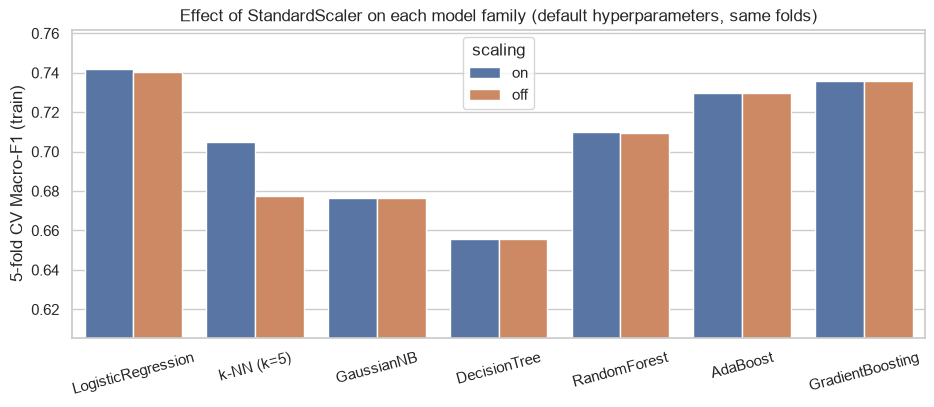

In [42]:
import warnings
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

MODELS = {                                    # default hyperparameters; tuning comes in Q2 / Q4
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'k-NN (k=5)': KNeighborsClassifier(),
    'GaussianNB': GaussianNB(),
    'DecisionTree': DecisionTreeClassifier(random_state=SEED),
    'RandomForest': RandomForestClassifier(random_state=SEED, n_jobs=-1),
    'AdaBoost': AdaBoostClassifier(random_state=SEED),
    'GradientBoosting': GradientBoostingClassifier(random_state=SEED),
}
cv = get_cv('clf')                            # the shared 5-fold StratifiedKFold (seed 463)

rows = []
with timer('scaling on/off for all models'):
    for name, model in MODELS.items():
        for scale in (True, False):
            pipe = Pipeline([('pre', build_preprocessor(scale=scale)), ('clf', model)])
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always', ConvergenceWarning)
                res = cross_validate(pipe, X_train, y_train, cv=cv, scoring='f1_macro',
                                     return_estimator=True, n_jobs=1)   # n_jobs=1 so warnings are captured here
            row = {'model': name, 'scaling': 'on' if scale else 'off',
                   'cv_macro_f1_mean': res['test_score'].mean(),
                   'cv_macro_f1_std': res['test_score'].std(),
                   'fit_time_s': res['fit_time'].mean(),
                   'convergence_warnings': sum(issubclass(w.category, ConvergenceWarning) for w in caught)}
            if name == 'LogisticRegression':
                row['lr_solver_iterations'] = np.mean([e.named_steps['clf'].n_iter_[0] for e in res['estimator']])
            rows.append(row)
            print(f"{name:20s} scaling={row['scaling']:3s}  CV Macro-F1 = "
                  f"{row['cv_macro_f1_mean']:.4f} ± {row['cv_macro_f1_std']:.4f}")
scal = pd.DataFrame(rows)
save_table(scal, 'q1c_scaling_sensitivity')

wide = scal.pivot(index='model', columns='scaling', values='cv_macro_f1_mean').reindex(list(MODELS))
wide['diff_on_minus_off'] = wide['on'] - wide['off']
print('\nCV Macro-F1, scaling on vs off:')
display(wide.round(4))
print('Logistic Regression solver behaviour:')
display(scal.loc[scal['model'] == 'LogisticRegression', ['scaling', 'lr_solver_iterations', 'convergence_warnings']])

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=scal, x='model', y='cv_macro_f1_mean', hue='scaling', hue_order=['on', 'off'], ax=ax)
ax.set_ylim(max(0, scal['cv_macro_f1_mean'].min() - 0.05), scal['cv_macro_f1_mean'].max() + 0.02)
ax.set_xlabel(''); ax.set_ylabel('5-fold CV Macro-F1 (train)')
ax.set_title('Effect of StandardScaler on each model family (default hyperparameters, same folds)')
ax.tick_params(axis='x', labelrotation=15)
save_fig(fig, 'q1c_scaling_sensitivity'); plt.show()

### Q1c.5 — Which transformation does each model family need? (empirical)

Instead of asserting the requirements, each model is **tried** on (a) raw categorical strings and (b) one-hot data that still contains NaN. If fitting fails, that transformation is required. The scaling column is the Macro-F1 difference from Q1c.4. (Categorical NB is not in this table: it needs discretised/ordinal input and is handled in Q2b.)

In [43]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Probe inputs, built from TRAIN only:
#  (a) categorical columns as raw strings, no NaN  -> tests whether a model needs encoding
#  (b) one-hot encoded, NaN kept in TotalCharges  -> tests whether a model needs imputation
X_probe_str = X_train.fillna({'TotalCharges': X_train['TotalCharges'].median()})
enc_only = ColumnTransformer([('num', 'passthrough', NUM_COLS),
                              ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS)])
X_probe_nan = enc_only.fit_transform(X_train)
print('NaN values in probe (b):', int(np.isnan(X_probe_nan).sum()))


def fits(model, X_in):
    """'yes' if the model can be fitted on X_in, otherwise 'no (<error type>)'."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            clone(model).fit(X_in, y_train)
        return 'yes'
    except Exception as e:
        return f'no ({type(e).__name__})'


req = pd.DataFrame([{'model': name,
                     'accepts_raw_strings': fits(m, X_probe_str),
                     'accepts_NaN': fits(m, X_probe_nan)} for name, m in MODELS.items()])
req['encoding_required'] = np.where(req['accepts_raw_strings'].str.startswith('no'), 'Yes', 'No')
req['imputation_required'] = np.where(req['accepts_NaN'].str.startswith('no'), 'Yes', 'No (native NaN support)')
req['macro_f1_scaled_minus_unscaled'] = req['model'].map(wide['diff_on_minus_off'])
save_table(req, 'q1c_preprocessing_requirements')
req

NaN values in probe (b): 10


,model,accepts_raw_strings,accepts_NaN,encoding_required,imputation_required,macro_f1_scaled_minus_unscaled
0,LogisticRegression,no (ValueError),no (ValueError),Yes,Yes,0.001495
1,k-NN (k=5),no (ValueError),no (ValueError),Yes,Yes,0.027225
2,GaussianNB,no (ValueError),no (ValueError),Yes,Yes,-0.000294
3,DecisionTree,no (ValueError),yes,Yes,No (native NaN support),-0.000009
4,RandomForest,no (ValueError),yes,Yes,No (native NaN support),0.000649
5,AdaBoost,no (ValueError),no (ValueError),Yes,Yes,0.000000
6,GradientBoosting,no (ValueError),no (ValueError),Yes,Yes,0.000000


## Q1c — Points for **you** to interpret in the report

*(Answer these from the outputs above in your own words; Claude does not write this text.)*

1. **Pipeline:** describe each step (numeric: median imputation → standardisation; categorical: most-frequent imputation → one-hot with `handle_unknown='ignore'`) and *why* each is there.
2. **Fit on train only:** what does the learned-statistics table prove? Why are the scaled validation means/stds close to, but not exactly, 0/1 — and why is that the *correct* behaviour?
3. **Missing `TotalCharges`:** what value did the 11 structurally-missing rows receive? Is the train median a sensible value for customers with `tenure = 0` (link to Q1a)? Name at least one alternative (e.g. 0, or `tenure × MonthlyCharges`) and its trade-off.
4. **Unseen categories:** what happens to a level never seen in training? Why is that safer than raising an error, and what information is lost?
5. **Scaling sensitivity:** which models change when scaling is switched off, by how much, and *why* (distance-based, regularisation penalty / solver convergence → LR iterations, split thresholds are scale-invariant, per-feature Gaussian)?
6. **Requirements table:** fill in the *reason* for each Yes/No (imputation, scaling, encoding) per model family; mention Categorical NB (needs discretised/ordinal input, see Q2b).
7. **Design decisions to justify:** `SeniorCitizen` treated as categorical; `TotalCharges` kept despite r = 0.9996; one-hot without `drop='first'` (collinearity of the dummy columns vs. regularised models).

---
# Q1d — Leakage demonstration: valid pipeline vs INVALID procedures

> ⚠️ Every procedure marked **`INVALID – demonstration only`** deliberately violates the protocol to show its effect. Its results are **not** used anywhere else in the project.

All experiments use **only the training split** for fitting and the shared 5-fold `StratifiedKFold` (seed 463), so valid and INVALID variants are compared on identical folds. In addition, each variant is fitted on the whole training split and scored on the **validation split**, which was never touched by any fitting step. Leakage shows up as a **CV estimate that is higher than the honest validation score**.

### Q1d.1 — Shared evaluation helper

In [44]:
import warnings
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

INVALID = 'INVALID – demonstration only'
cv = get_cv('clf')                                   # the shared 5-fold StratifiedKFold
X_val, y_val = parts['X_val'], parts['y_val']
# class_weight='balanced' so the classifier does not collapse to the majority class
# (otherwise Macro-F1 would sit at ~0.42 regardless of the features and leakage would be invisible)
LR = LogisticRegression(max_iter=1000, class_weight='balanced')

# Chance level for comparison: expected Macro-F1 of random guessing that labels 50% of rows as churn.
# Per class with prevalence p: precision = p, recall = 0.5  ->  F1 = 2 * p * 0.5 / (p + 0.5)
p_pos = y_val.mean()
CHANCE_MACRO_F1 = np.mean([2 * p * 0.5 / (p + 0.5) for p in (p_pos, 1 - p_pos)])
print(f'Chance-level Macro-F1 (balanced random guessing, churn rate {p_pos:.3f}): {CHANCE_MACRO_F1:.3f}')


def evaluate(experiment, method, est, X_tr, y_tr, X_va, leaky_step=None):
    """Return the 5-fold CV Macro-F1 on (X_tr, y_tr) and the Macro-F1 on the validation split.

    VALID   (leaky_step=None): `est` is a full Pipeline -> every learned step is re-fitted inside each CV fold.
    INVALID (leaky_step given): `leaky_step` is fitted ONCE on ALL training rows (labels included)
            before cross-validation, so information from the held-out folds leaks into training.
    """
    if leaky_step is None:
        X_tr_used, X_va_used = X_tr, X_va
    else:
        step = clone(leaky_step).fit(X_tr, y_tr)
        X_tr_used, X_va_used = step.transform(X_tr), step.transform(X_va)
    cv_scores = cross_val_score(est, X_tr_used, y_tr, cv=cv, scoring='f1_macro', n_jobs=-1)
    val_pred = clone(est).fit(X_tr_used, y_tr).predict(X_va_used)
    row = {'experiment': experiment,
           'method': method if leaky_step is None else f'{method} [{INVALID}]',
           'is_invalid': leaky_step is not None,
           'cv_macro_f1': cv_scores.mean(), 'cv_std': cv_scores.std(),
           'val_macro_f1': f1_score(y_val, val_pred, average='macro')}
    row['optimism_cv_minus_val'] = row['cv_macro_f1'] - row['val_macro_f1']
    return row

Chance-level Macro-F1 (balanced random guessing, churn rate 0.265): 0.471


### Q1d.2 — D1: feature selection on noise columns

200 columns of pure Gaussian noise (no relation to churn) are generated; `SelectKBest(f_classif)` keeps the best k columns, then Logistic Regression.

* **D1a — only noise columns.** Any score above chance level (`CHANCE_MACRO_F1` ≈ 0.47 for this class ratio, computed in Q1d.1 — not 0.5) is an artefact. Run on a small subsample of the training split (n = 200) and on the full training split (n = 4,225).
* **D1b — the 46 real features + the 200 noise columns.** The cell also counts how many noise columns end up among the 20 selected features.

**Valid:** `SelectKBest` inside the pipeline (re-fitted in each fold). **INVALID:** `SelectKBest` fitted once on all training rows, then CV. Noise is redrawn 10 times (seeds 1463 … 1472) so the result does not depend on one lucky draw.

In [45]:
N_NOISE, N_NOISE_SEEDS = 200, 10
SUB_SIZES = [200, len(y_train)]
noise_cols = [f'noise_{j}' for j in range(N_NOISE)]
y_tr_arr = y_train.to_numpy()

d1, noise_selected = [], []
with timer('D1 noise + SelectKBest'), warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for r in range(N_NOISE_SEEDS):
        rng = np.random.default_rng(SEED + 1000 + r)
        noise_tr = rng.normal(size=(len(y_train), N_NOISE))
        noise_va = rng.normal(size=(len(y_val), N_NOISE))

        # D1a: ONLY noise columns (no real signal at all) -> honest Macro-F1 should be at chance level
        for n in SUB_SIZES:
            rows_ = rng.choice(len(y_train), size=n, replace=False) if n < len(y_train) else np.arange(len(y_train))
            Xn, yn = noise_tr[rows_], y_tr_arr[rows_]
            exp = f'D1a pure noise ({N_NOISE} cols, k=10), n_train={n}'
            d1.append(evaluate(exp, 'SelectKBest inside pipeline',
                               Pipeline([('select', SelectKBest(f_classif, k=10)), ('clf', LR)]),
                               Xn, yn, noise_va) | {'noise_draw': r})
            d1.append(evaluate(exp, 'SelectKBest fitted on all training rows before CV',
                               LR, Xn, yn, noise_va, leaky_step=SelectKBest(f_classif, k=10)) | {'noise_draw': r})

        # D1b: real features + the same noise columns (full training split)
        Xtr_rn = pd.concat([X_train, pd.DataFrame(noise_tr, index=X_train.index, columns=noise_cols)], axis=1)
        Xva_rn = pd.concat([X_val, pd.DataFrame(noise_va, index=X_val.index, columns=noise_cols)], axis=1)
        ct = ColumnTransformer([('base', build_preprocessor(), NUM_COLS + CAT_COLS),
                                ('noise', 'passthrough', noise_cols)])
        exp = f'D1b real (46) + noise ({N_NOISE}) features, k=20'
        d1.append(evaluate(exp, 'SelectKBest inside pipeline',
                           Pipeline([('pre', ct), ('select', SelectKBest(f_classif, k=20)), ('clf', LR)]),
                           Xtr_rn, y_train, Xva_rn) | {'noise_draw': r})
        d1.append(evaluate(exp, 'SelectKBest fitted on all training rows before CV',
                           LR, Xtr_rn, y_train, Xva_rn,
                           leaky_step=Pipeline([('pre', ct), ('select', SelectKBest(f_classif, k=20))])) | {'noise_draw': r})

        # Check: how many of the 20 columns kept by SelectKBest in D1b are noise columns?
        sel = Pipeline([('pre', clone(ct)), ('select', SelectKBest(f_classif, k=20))]).fit(Xtr_rn, y_train)
        kept = sel.named_steps['pre'].get_feature_names_out()[sel.named_steps['select'].get_support()]
        noise_selected.append(int(sum(name.startswith('noise__') for name in kept)))

d1_df = pd.DataFrame(d1)
d1_df.to_csv(TABLES_DIR / 'q1d_noise_selection_all_draws.csv', index=False)
print(f'D1b: number of noise columns among the 20 selected features, per noise draw: {noise_selected}')
(d1_df.groupby(['experiment', 'method'], sort=False)[['cv_macro_f1', 'val_macro_f1', 'optimism_cv_minus_val']]
      .mean().round(4))

[timer] D1 noise + SelectKBest: 6.418 s
D1b: number of noise columns among the 20 selected features, per noise draw: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


cv_macro_f1  \
experiment                                    method                                                            
D1a pure noise (200 cols, k=10), n_train=200  SelectKBest inside pipeline                              0.5032   
                                              SelectKBest fitted on all training rows before ...       0.6616   
D1a pure noise (200 cols, k=10), n_train=4225 SelectKBest inside pipeline                              0.4740   
                                              SelectKBest fitted on all training rows before ...       0.5106   
D1b real (46) + noise (200) features, k=20    SelectKBest inside pipeline                              0.7208   
                                              SelectKBest fitted on all training rows before ...       0.7206   

                                                                                                  val_macro_f1  \
experiment                                    method                                                             
D1a pure noise (200 cols, k=10), n_train=200  SelectKBest inside pipeline                               0.4838   
                                              SelectKBest fitted on all training rows before ...        0.4838   
D1a pure noise (200 cols, k=10), n_train=4225 SelectKBest inside pipeline                               0.4720   
                                              SelectKBest fitted on all training rows before ...        0.4720   
D1b real (46) + noise (200) features, k=20    SelectKBest inside pipeline                               0.6947   
                                              SelectKBest fitted on all training rows before ...        0.6947   

                                                                                                  optimism_cv_minus_val  
experiment                                    method                                                                     
D1a pure noise (200 cols, k=10), n_train=200  SelectKBest inside pipeline                                        0.0195  
                                              SelectKBest fitted on all training rows before ...                 0.1779  
D1a pure noise (200 cols, k=10), n_train=4225 SelectKBest inside pipeline                                        0.0019  
                                              SelectKBest fitted on all training rows before ...                 0.0386  
D1b real (46) + noise (200) features, k=20    SelectKBest inside pipeline                                        0.0261  
                                              SelectKBest fitted on all training rows before ...                 0.0259

### Q1d.3 — D2: target encoding of an ID-like column

`customerID` is unique per customer. Its target encoding (mean churn per ID) computed on all training rows is essentially **the row's own label** → direct label leakage.

* **Valid:** `TargetEncoder` inside the pipeline. During `fit` it uses internal cross-fitting, so a row's encoding never uses its own label; IDs in a held-out fold are unseen and get the global mean.
* **INVALID:** the encoder is fitted once on all training rows and those encodings are used inside CV.
* **Baseline:** the same model without the ID column, for reference.

In [46]:
from sklearn.preprocessing import TargetEncoder

Xtr_id = X_train.assign(**{TELCO_ID: ids.loc[X_train.index].to_numpy()})
Xva_id = X_val.assign(**{TELCO_ID: ids.loc[X_val.index].to_numpy()})


def with_id_encoder():
    """Standard preprocessing + target encoding of customerID."""
    return ColumnTransformer([
        ('base', build_preprocessor(), NUM_COLS + CAT_COLS),
        ('te_id', TargetEncoder(target_type='binary', random_state=SEED), [TELCO_ID]),
    ])


d2_rows = []
exp = 'D2 target-encoded customerID'
with timer('D2 target encoding'), warnings.catch_warnings():
    warnings.simplefilter('ignore')
    d2_rows.append(evaluate(exp, 'baseline: no ID column',
                            Pipeline([('pre', build_preprocessor()), ('clf', LR)]), X_train, y_train, X_val))
    d2_rows.append(evaluate(exp, 'TargetEncoder inside pipeline (cross-fitted)',
                            Pipeline([('pre', with_id_encoder()), ('clf', LR)]), Xtr_id, y_train, Xva_id))
    d2_rows.append(evaluate(exp, 'target encoding fitted on all training rows before CV',
                            LR, Xtr_id, y_train, Xva_id, leaky_step=with_id_encoder()))

# How much label information does the leaky ID column carry?
leaky_te = with_id_encoder().fit(Xtr_id, y_train)
enc_col = leaky_te.transform(Xtr_id)[:, -1]
print(f'[{INVALID}] correlation(encoded customerID, Churn) on train = {np.corrcoef(enc_col, y_train)[0, 1]:.3f}')
print(f'distinct encoded values on validation (all IDs unseen): {np.unique(leaky_te.transform(Xva_id)[:, -1]).size}')
pd.DataFrame(d2_rows).round(4)

[timer] D2 target encoding: 0.451 s
[INVALID – demonstration only] correlation(encoded customerID, Churn) on train = 1.000
distinct encoded values on validation (all IDs unseen): 1


c:\Users\berks\CENG463_Midterm\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


,experiment,method,is_invalid,cv_macro_f1,cv_std,val_macro_f1,optimism_cv_minus_val
0,D2 target-encoded customerID,baseline: no ID column,False,0.7225,0.0109,0.7067,0.0158
1,D2 target-encoded customerID,TargetEncoder inside pipeline (cross-fitted),False,0.7223,0.0115,0.7067,0.0155
2,D2 target-encoded customerID,target encoding fitted on all training rows be...,True,1.0000,0.0000,0.4235,0.5765


### Q1d.4 — D3: imputation + scaling fitted on all training rows

The median/mean/std are computed once on all 4,225 training rows (including the rows that later act as CV validation folds) and then CV is run. These statistics do not use the labels, so the effect is expected to be **small** — it is reported as it comes out. Note that the final model and its validation score are identical in both variants; only the CV estimate can differ.

In [47]:
d3_rows = []
with timer('D3 preprocessing on all rows'), warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for name, model in [('LogisticRegression', LR), ('k-NN (k=5)', KNeighborsClassifier())]:
        exp = f'D3 imputation+scaling, {name}'
        d3_rows.append(evaluate(exp, 'preprocessing inside pipeline',
                                Pipeline([('pre', build_preprocessor()), ('clf', model)]),
                                X_train, y_train, X_val))
        d3_rows.append(evaluate(exp, 'preprocessing fitted on all training rows before CV',
                                model, X_train, y_train, X_val, leaky_step=build_preprocessor()))
pd.DataFrame(d3_rows).round(4)

[timer] D3 preprocessing on all rows: 0.634 s


,experiment,method,is_invalid,cv_macro_f1,cv_std,val_macro_f1,optimism_cv_minus_val
0,"D3 imputation+scaling, LogisticRegression",preprocessing inside pipeline,False,0.7225,0.0109,0.7067,0.0158
1,"D3 imputation+scaling, LogisticRegression",preprocessing fitted on all training rows befo...,True,0.7228,0.0109,0.7067,0.0161
2,"D3 imputation+scaling, k-NN (k=5)",preprocessing inside pipeline,False,0.7049,0.0228,0.6934,0.0115
3,"D3 imputation+scaling, k-NN (k=5)",preprocessing fitted on all training rows befo...,True,0.7053,0.0225,0.6934,0.0119


### Q1d.5 — Summary: CV estimate vs honest validation score

For D1 the numbers are averaged over the 10 noise draws. Rows labelled **INVALID** are for demonstration only and are not used anywhere else in the project.

,experiment,label,cv_macro_f1,cv_std,val_macro_f1,optimism_cv_minus_val
0,"D1a pure noise (200 cols, k=10), n_train=200",valid,0.5032,0.0698,0.4838,0.0195
1,"D1a pure noise (200 cols, k=10), n_train=200",INVALID,0.6616,0.0607,0.4838,0.1779
2,"D1a pure noise (200 cols, k=10), n_train=4225",valid,0.4740,0.0115,0.4720,0.0019
3,"D1a pure noise (200 cols, k=10), n_train=4225",INVALID,0.5106,0.0131,0.4720,0.0386
4,"D1b real (46) + noise (200) features, k=20",valid,0.7208,0.0079,0.6947,0.0261
5,"D1b real (46) + noise (200) features, k=20",INVALID,0.7206,0.0080,0.6947,0.0259
6,D2 target-encoded customerID,baseline (no ID),0.7225,0.0109,0.7067,0.0158
7,D2 target-encoded customerID,valid,0.7223,0.0115,0.7067,0.0155
8,D2 target-encoded customerID,INVALID,1.0000,0.0000,0.4235,0.5765
9,"D3 imputation+scaling, LogisticRegression",valid,0.7225,0.0109,0.7067,0.0158


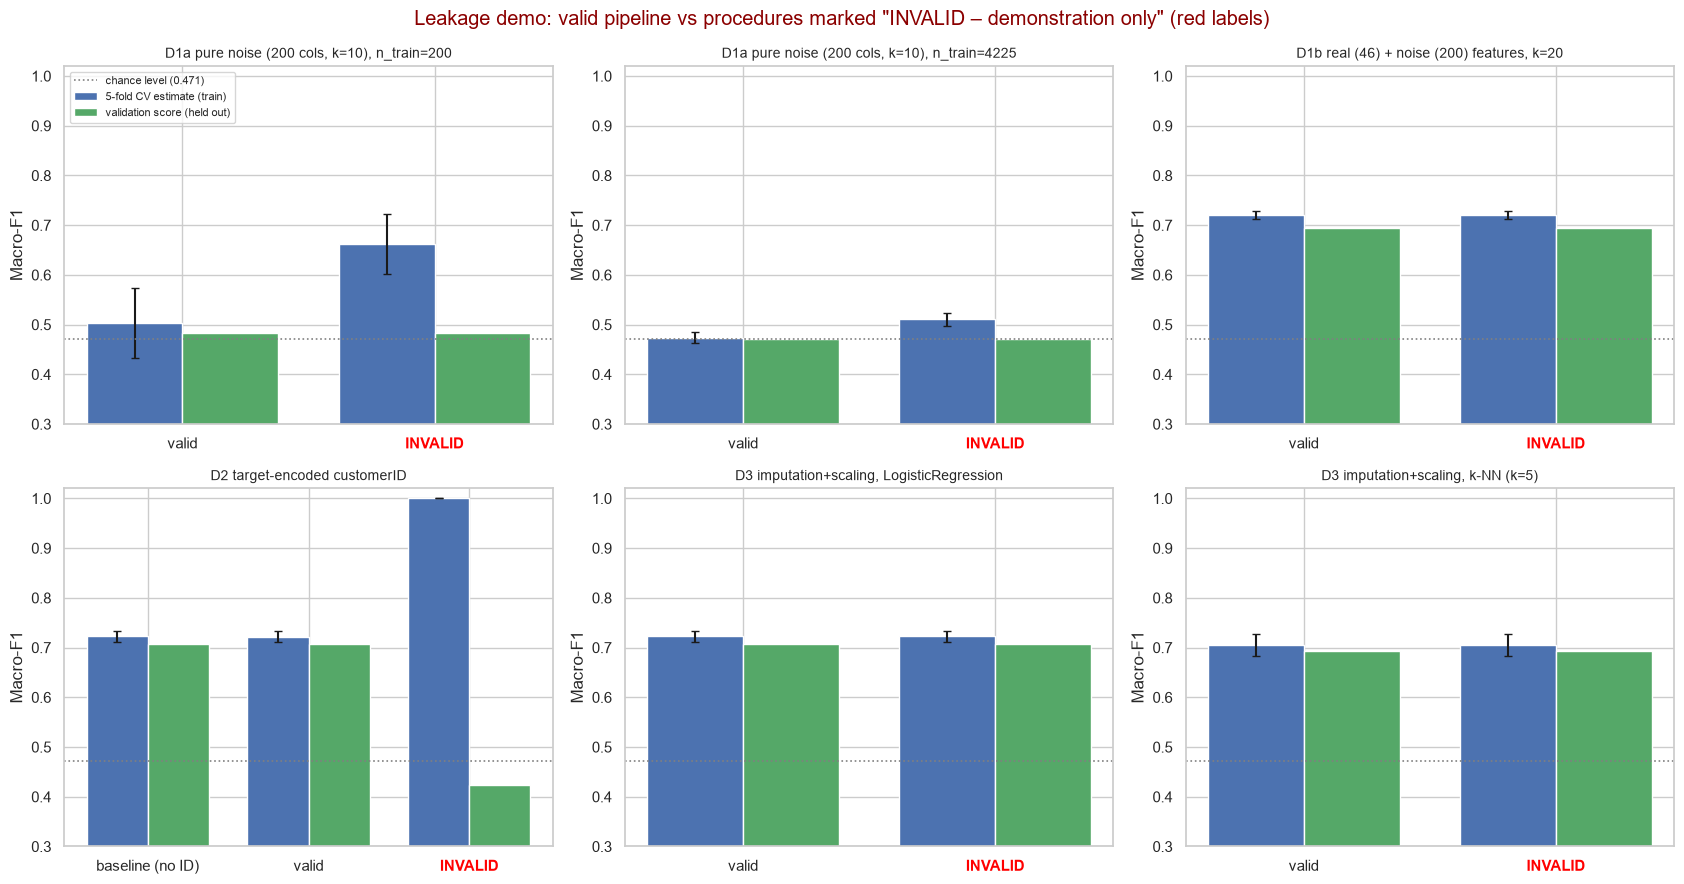

In [48]:
d1_summary = (d1_df.groupby(['experiment', 'method', 'is_invalid'], sort=False)
                   .agg(cv_macro_f1=('cv_macro_f1', 'mean'),
                        cv_std=('cv_std', 'mean'),                    # mean fold-std over the noise draws
                        cv_std_over_draws=('cv_macro_f1', 'std'),
                        val_macro_f1=('val_macro_f1', 'mean'),
                        optimism_cv_minus_val=('optimism_cv_minus_val', 'mean'))
                   .reset_index())
summary = pd.concat([d1_summary, pd.DataFrame(d2_rows + d3_rows)], ignore_index=True)
summary['is_invalid'] = summary['is_invalid'].astype(bool)
summary['label'] = np.select([summary['is_invalid'].to_numpy(), summary['method'].str.startswith('baseline').to_numpy()],
                             ['INVALID', 'baseline (no ID)'], default='valid')
save_table(summary.drop(columns='label'), 'q1d_leakage_summary')
display(summary[['experiment', 'label', 'cv_macro_f1', 'cv_std', 'val_macro_f1', 'optimism_cv_minus_val']].round(4))

exps = list(summary['experiment'].unique())
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, e in zip(axes.ravel(), exps):
    d = summary[summary['experiment'] == e]
    xpos, w = np.arange(len(d)), 0.38
    ax.bar(xpos - w / 2, d['cv_macro_f1'], w, yerr=d['cv_std'], capsize=3, color='#4C72B0', label='5-fold CV estimate (train)')
    ax.bar(xpos + w / 2, d['val_macro_f1'], w, color='#55A868', label='validation score (held out)')
    ax.axhline(CHANCE_MACRO_F1, ls=':', color='gray', lw=1.2, label=f'chance level ({CHANCE_MACRO_F1:.3f})')
    ax.set_xticks(xpos); ax.set_xticklabels(d['label'])
    for tick, lab in zip(ax.get_xticklabels(), d['label']):
        if lab == 'INVALID':
            tick.set_color('red'); tick.set_fontweight('bold')
    ax.set_ylim(0.3, 1.02); ax.set_ylabel('Macro-F1'); ax.set_title(e, fontsize=10)
for ax in axes.ravel()[len(exps):]:
    ax.axis('off')
axes.ravel()[0].legend(loc='upper left', fontsize=8)
fig.suptitle(f'Leakage demo: valid pipeline vs procedures marked "{INVALID}" (red labels)', color='darkred')
fig.tight_layout()
save_fig(fig, 'q1d_leakage_cv_vs_val'); plt.show()

## Q1d — Points for **you** to interpret in the report

*(Answer these from the outputs above in your own words; Claude does not write this text.)*

1. **Size of the effect:** for each experiment, compare valid vs INVALID on (a) the 5-fold CV estimate and (b) the validation score. How large is the optimism (CV − validation) of each?
2. **Mechanism:** for each INVALID procedure, *which information from the held-out folds* reached the training step? (feature-selection statistics; target means; mean/std/median.)
3. **Pure noise, n = 200 vs n = 4,225:** why is the inflation larger with few rows and many candidate features (multiple comparisons, p ≫ n)? What should the honest score be for pure noise?
4. **Real features + noise:** why is the leakage effect smaller here? Does "small effect on this dataset" mean the procedure is acceptable?
5. **Target-encoded `customerID`:** why does the INVALID CV look almost perfect, and why does the validation score not follow? How does `TargetEncoder` inside the pipeline (internal cross-fitting) avoid this? Give a realistic example where such an ID-like/high-cardinality feature appears.
6. **Scaling/imputation on all training rows:** report the difference honestly. Why is it small here (unsupervised statistics, large n)? Why is it still a protocol violation (and when could it matter more)?
7. **General lesson:** when is a CV estimate trustworthy? Connect to the rule "every learned step inside the pipeline".

---
# Q1e — Dataset audit table, protocol diagram and failure modes

### Q1e.1 — Dataset audit table

One row per column of the raw CSV: role, stored type, missing count/percentage, number of unique values, range (numeric) or most frequent value (categorical), and a factual note from the Q1a findings. Saved as `results/tables/q1e_dataset_audit.csv/.tex`.

The **protocol diagram** is a TikZ figure in the report: `report/protocol_diagram.tex` (Figure `fig:protocol`, included in Section 3 of `main.tex`).

In [49]:
X_aud = raw.copy()
X_aud['TotalCharges'] = pd.to_numeric(X_aud['TotalCharges'], errors='coerce')
n_blank = int(raw['TotalCharges'].astype(str).str.strip().eq('').sum())
r_tc = X_aud['TotalCharges'].corr(X_aud['tenure'] * X_aud['MonthlyCharges'])

# Factual flags from Q1a (no interpretation)
notes = {
    TELCO_ID: 'unique per row (identifier); excluded from the features',
    'tenure': f'{int((X_aud["tenure"] == 0).sum())} rows with tenure = 0',
    'TotalCharges': (f'stored as text; {n_blank} blank strings (all with tenure = 0) -> NaN; '
                     f'Pearson r = {r_tc:.4f} with tenure x MonthlyCharges'),
    'SeniorCitizen': 'stored as 0/1; treated as categorical',
    'MultipleLines': "level 'No phone service' fully determined by PhoneService = No",
    TELCO_TARGET: f'imbalanced: {(raw[TELCO_TARGET] == "Yes").mean():.1%} Yes',
}
notes.update({s: "level 'No internet service' fully determined by InternetService = No" for s in services})

audit_rows = []
for c in raw.columns:
    s = X_aud[c]
    row = {'column': c, 'role': roles[c], 'raw_dtype': str(raw[c].dtype),
           'missing_n': int(s.isna().sum()), 'missing_pct': 100 * s.isna().mean(),
           'n_unique': int(s.nunique())}
    if c in NUM_COLS:
        row['range_or_most_frequent'] = f'{s.min():g} to {s.max():g}'
    else:
        vc = s.value_counts()
        row['range_or_most_frequent'] = f'{vc.index[0]} ({vc.iloc[0] / len(s):.1%})'
    row['note'] = notes.get(c, '')
    audit_rows.append(row)
audit = pd.DataFrame(audit_rows)
save_table(audit, 'q1e_dataset_audit', float_format='%.2f')
print(f'{len(raw)} rows x {raw.shape[1]} columns; exact duplicate rows: {int(raw.duplicated().sum())}; '
      f'feature-duplicate groups (excl. customerID): {len(per_group)}')
audit

7043 rows x 21 columns; exact duplicate rows: 0; feature-duplicate groups (excl. customerID): 33


,column,role,raw_dtype,missing_n,missing_pct,n_unique,range_or_most_frequent,note
0,customerID,ID (not a feature),str,0,0.000000,7043,7590-VHVEG (0.0%),unique per row (identifier); excluded from the...
1,gender,categorical,str,0,0.000000,2,Male (50.5%),
2,SeniorCitizen,categorical,int64,0,0.000000,2,0 (83.8%),stored as 0/1; treated as categorical
3,Partner,categorical,str,0,0.000000,2,No (51.7%),
4,Dependents,categorical,str,0,0.000000,2,No (70.0%),
5,tenure,numeric,int64,0,0.000000,73,0 to 72,11 rows with tenure = 0
6,PhoneService,categorical,str,0,0.000000,2,Yes (90.3%),
7,MultipleLines,categorical,str,0,0.000000,3,No (48.1%),level 'No phone service' fully determined by P...
8,InternetService,categorical,str,0,0.000000,3,Fiber optic (44.0%),
9,OnlineSecurity,categorical,str,0,0.000000,3,No (49.7%),level 'No internet service' fully determined b...


### Q1e.2 — Protocol guards (evidence for the failure-mode discussion)

Three automatic checks:
1. **Split integrity:** the saved train/val/test indices are disjoint and cover every row.
2. **Near-duplicates across splits:** how many feature-identical customer groups (Q1a.4) are shared between train, validation and test.
3. **Data fingerprint:** SHA-256 hashes of the data and split files are stored in `results/data_fingerprint.json` on the first run; later runs compare against them and warn if a file has changed.

In [50]:
import hashlib
import json

# --- Guard 1: split integrity (disjoint, complete)
split_rows = pd.read_csv(CLF_SPLIT_FILE)
sets = {p: set(split_rows.loc[split_rows['split'] == p, 'row']) for p in ('train', 'val', 'test')}
assert not (sets['train'] & sets['val']) and not (sets['train'] & sets['test']) and not (sets['val'] & sets['test'])
assert len(sets['train'] | sets['val'] | sets['test']) == len(raw)
print('[ok] train/val/test are disjoint and cover all', len(raw), 'rows')

# --- Guard 2: feature-identical customers that fall into different splits (from Q1a.4)
group_splits = dup_groups.groupby(group_key)['split'].agg(set)
cross = pd.DataFrame([
    {'pair': f'{a} & {b}',
     'groups': int(sum({a, b} <= s for s in group_splits)),
     'rows_in_those_groups': int(dup_groups[group_key.map(lambda k: {a, b} <= group_splits[k])].shape[0])}
    for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]
])
save_table(cross, 'q1e_duplicates_across_splits')
print(f'Feature-duplicate groups: {len(group_splits)} (rows: {len(dup_groups)}). Groups shared between splits:')
display(cross)

# --- Guard 3: fingerprint of data and split files (detects silent changes between runs)
def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

FINGERPRINT_FILE = RESULTS_DIR / 'data_fingerprint.json'
tracked = [DATA_DIR / 'telco_churn.csv', DATA_DIR / 'california_housing.csv', CLF_SPLIT_FILE, REG_SPLIT_FILE]
current = {p.relative_to(ROOT).as_posix(): sha256(p) for p in tracked}
if FINGERPRINT_FILE.exists():
    saved = json.loads(FINGERPRINT_FILE.read_text())
    changed = [k for k in current if saved.get(k) != current[k]]
    if changed:
        # A warning, not an error: line-ending conversion by git on another OS also changes the hash.
        print('[WARNING] these files differ from the fingerprint created on', saved.get('_created'), ':', changed)
    else:
        print('[ok] data and split files are unchanged since', saved.get('_created'))
else:
    FINGERPRINT_FILE.write_text(json.dumps(current | {'_created': pd.Timestamp.now().isoformat(timespec='seconds')}, indent=2))
    print('[ok] fingerprint created:', FINGERPRINT_FILE.relative_to(ROOT).as_posix())
current

[ok] train/val/test are disjoint and cover all 7043 rows
Feature-duplicate groups: 33 (rows: 73). Groups shared between splits:


,pair,groups,rows_in_those_groups
0,train & val,12,28
1,train & test,11,28
2,val & test,4,11


[ok] data and split files are unchanged since 2026-11-25T18:51:56


{'data/telco_churn.csv': '88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a',
 'data/california_housing.csv': '7192af0bf33e94141194cfd91958c62d66262dc40c07cc2e6fbe0b2d02b0e1b3',
 'results/splits/clf_split_indices.csv': '2428c083cc13528390361b34134590e29fe9c9c345ae368166be3c951caa1340',
 'results/splits/reg_split_indices.csv': 'dcc8ffe9be3ac08325d88f565482671c175ada66a4f150e0e7d5ef01bfb2af8e'}

## Q1e — Points for **you** to write in the report

*(Write these in your own words; Claude does not write this text.)*

1. **Audit table:** briefly comment on every column that carries a note (ID, `TotalCharges`, `tenure`, `SeniorCitizen`, the dependent service levels, the target). Which audit findings changed a design decision, and which did not?
2. **Protocol diagram** (`report/protocol_diagram.tex`, Figure `fig:protocol`): walk the reader through it and say at which stage each of Q1–Q5 happens.
3. **At least three failure modes that could invalidate the results even though the code runs without errors.** For each: *what* goes wrong, *how it would bias* the results, *how it is detected/prevented* in this project (cite the evidence above where possible). Candidate topics to choose from or add to:
   - near-duplicate customers that fall into different splits (see the table above);
   - information from the future / after the churn event hidden in features (how are `tenure` and `TotalCharges` measured for customers who already churned?);
   - the test set being consulted more than once (selection on test, "just one more run");
   - over-using the validation set for many comparisons (selection bias on validation);
   - preprocessing or feature selection accidentally fitted outside the pipeline in a later notebook (Q1d shows the effect);
   - the data or split file silently changing between runs (the fingerprint check above);
   - a single fixed split / seed giving a lucky or unlucky estimate (variance of the estimate);
   - accuracy reported on imbalanced data instead of Macro-F1 / PR-AUC;
   - dataset shift: a single snapshot of one company, so conclusions may not transfer to other periods or markets.